# Notebook 1 — EDA & Preprocessing Tweet Banjir
**Proyek UTS Kecerdasan Artifisial: Agen Cerdas Tanggap Banjir Ciledug**
Izvio Prijaya Mumin (2611600087) · Magister Komputer · Universitas Budi Luhur

Tujuan notebook ini:
1. Memuat dataset *Semantic Role Labeling Datasets for Crisis Event* (Ariyanto dkk., 2025), subset **banjir**.
2. Menurunkan **label tingkat tweet** dari label tingkat token: `laporan` (kejadian banjir nyata) vs `bukan_laporan`.
3. Mengekstrak entitas **lokasi** yang sudah dianotasi (dipakai di Notebook 4).
4. Menyaring tweet berbahasa Melayu.
5. Preprocessing teks: case folding → cleaning → normalisasi slang → stopword removal → stemming (Sastrawi).
6. Membagi data latih/uji secara stratified (80:20).

In [1]:
import os, re, subprocess, sys
from pathlib import Path

# Colab: clone repo agar data tersedia; lokal: pindah ke root repo
if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "Sastrawi"], check=True)
    if not Path("/content/repo").exists():
        subprocess.run(["git", "clone", "-q", "https://github.com/izviopm/uts-ai-banjir-ciledug.git", "/content/repo"], check=True)
    os.chdir("/content/repo")
elif Path("../data").exists():
    os.chdir("..")
print("Working dir:", Path.cwd())

Working dir: D:\Izvio\Document\Universitas Budi Luhur\Semester 1\03 - Kecerdasan Artifisial\UTS\penelitian-banjir-ciledug


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

sns.set_theme(style="whitegrid")
RAW = Path("data/raw/mendeley-srl-crisis/all-labeled-data-with-english-translation.csv")
OUT = Path("data/processed"); OUT.mkdir(parents=True, exist_ok=True)
FIG = Path("laporan/gambar"); FIG.mkdir(parents=True, exist_ok=True)

tok = pd.read_csv(RAW, keep_default_na=False)
print(tok.shape)
tok.head(12)

(99206, 6)


,text_id,id,token_in_Indonesian,token_in_English,entity,argument
0,BAN-00001,BAN-00001.001,13,13,O,O
1,BAN-00001,BAN-00001.002,janji,promise,O,O
2,BAN-00001,BAN-00001.003,akan,will,O,O
3,BAN-00001,BAN-00001.004,mencari,look for,O,O
4,BAN-00001,BAN-00001.005,solusi,solution,O,O
5,BAN-00001,BAN-00001.006,banjir,flood,B-EVE,FALSE-EVENT
6,BAN-00001,BAN-00001.007,jakarta,Jakarta,B-LOC,PLACE-ARG
7,BAN-00001,BAN-00001.008,dan,And,O,O
8,BAN-00001,BAN-00001.009,kemacetan,congestion,O,O
9,BAN-00001,BAN-00001.010,jakarta,Jakarta,B-LOC,PLACE-ARG


## 1. Struktur data
Data berbentuk **satu baris per token**. Kolom `entity` berisi label NER (skema BIO: `LOC`, `PLOC`, `ORG`, `ARG`, `EVE`),
kolom `argument` berisi label Semantic Role Labeling (mis. `FLOOD-EVENT`, `FALSE-EVENT`, `PLACE-ARG`, `STREET-ARG`).
Prefiks `text_id` menunjukkan jenis krisis: **BAN** = banjir, GEM = gempa, KEB = kebakaran, KEC = kecelakaan.

In [3]:
tok["jenis"] = tok.text_id.str.split("-").str[0]
print(tok.groupby("jenis").text_id.nunique().rename("jumlah_tweet"))
ban = tok[tok.jenis == "BAN"].copy()
ban.argument.value_counts()

jenis
BAN    1250
GEM     906
KEB    1128
KEC     866
Name: jumlah_tweet, dtype: int64


argument
O                      22045
PLACE-ARG               2894
FALSE-EVENT             1125
OFFICER-ARG              527
FLOOD-EVENT              467
INFORMATION-ARG          385
TIME-ARG                 354
REASON-ARG               323
AFFECTEDOBJECTS-ARG      260
STREET-ARG               205
WOUNDVICTIM-ARG           99
DEATHVICTIM-ARG           93
EARTHQUAKE-EVENT           3
Name: count, dtype: int64

## 2. Label tingkat tweet
Anotator memberi label `FLOOD-EVENT` pada kata pemicu (trigger) jika tweet **melaporkan kejadian banjir yang nyata**,
dan `FALSE-EVENT` jika kata "banjir" muncul tetapi bukan laporan kejadian (opini, politik, doa, kiasan).

Aturan: tweet berlabel **`laporan`** jika memiliki minimal satu token `FLOOD-EVENT`, selain itu **`bukan_laporan`**.

In [4]:
def gabung_lokasi(g):
    """Gabungkan token ber-tag B-/I-LOC, B-/I-PLOC, atau argumen STREET menjadi frasa lokasi."""
    frasa, cur = [], []
    for t, e, a in zip(g.token_in_Indonesian, g.entity, g.argument):
        if e.endswith("LOC") or a == "STREET-ARG":
            if e.startswith("B-") and cur:
                frasa.append(" ".join(cur)); cur = []
            cur.append(t)
        elif cur:
            frasa.append(" ".join(cur)); cur = []
    if cur:
        frasa.append(" ".join(cur))
    return list(dict.fromkeys(frasa))  # unik, urutan tetap

tweets = (ban.groupby("text_id", sort=True)
          .apply(lambda g: pd.Series({
              "text_raw": " ".join(g.token_in_Indonesian),
              "label": "laporan" if (g.argument == "FLOOD-EVENT").any() else "bukan_laporan",
              "locations": gabung_lokasi(g),
          }), include_groups=False)
          .reset_index().rename(columns={"text_id": "id"}))
print(tweets.label.value_counts())
tweets.sample(6, random_state=1)

label
bukan_laporan    881
laporan          369
Name: count, dtype: int64


,id,text_raw,label,locations
408,BAN-01159,2 korban banjir bandang di dairi berhasil dite...,laporan,[dairi]
711,BAN-01462,breaking news ! aktivitas banjir di jakarta ba...,bukan_laporan,[jakarta barat]
1114,BAN-01865,penampakan banjir dari udara di kawasan sempaj...,laporan,"[sempaja, samarinda]"
699,BAN-01450,via : jalan menuju stasiun bandung pintu selat...,bukan_laporan,[bandung]
236,BAN-00237,regrann from - pmi siap bantu masyarakat yang ...,bukan_laporan,[]
119,BAN-00120,lurah kampung melayu berani katakan penanganan...,bukan_laporan,[kampung melayu]


## 3. Penyaringan tweet berbahasa Melayu
Dataset dikumpulkan dengan kata kunci "banjir", sehingga ikut terambil tweet dari Malaysia.
Kami memakai heuristik penanda leksikal khas Melayu/Malaysia (kata dan nama tempat). Tweet dengan **≥ 1 penanda** dibuang.

In [5]:
PENANDA_MELAYU = {
    "mangsa", "pemindahan", "takkan", "sahaja", "kerana", "bomba", "jkm", "apm", "nadma",
    "malaysia", "johor", "kelantan", "terengganu", "pahang", "kuantan", "mersing", "sabah", "sarawak",
    "selangor", "kedah", "melaka", "segamat", "kemaman", "dungun", "balairaya",
    "tarikh", "laluan", "kenderaan", "berehat", "pusat pemindahan",
}
PENANDA_KATA = {p for p in PENANDA_MELAYU if " " not in p}
PENANDA_FRASA = [p for p in PENANDA_MELAYU if " " in p]

def skor_melayu(teks):
    kata = set(teks.lower().split())
    return len(kata & PENANDA_KATA) + sum(f in teks.lower() for f in PENANDA_FRASA)

tweets["skor_melayu"] = tweets.text_raw.map(skor_melayu)
melayu = tweets[tweets.skor_melayu >= 1]
print(f"Tweet terindikasi Melayu: {len(melayu)} dari {len(tweets)}")
print(melayu.label.value_counts())
melayu.text_raw.head(8).tolist()

Tweet terindikasi Melayu: 30 dari 1250
label
bukan_laporan    29
laporan           1
Name: count, dtype: int64


['ayuh kita bersama menjayakan misi bantuan mangsa banjir di mersing pada 3 jangan ( 9 pagi - 1 petang ) di ibu pejabat saj ranhill larkin',
 'anak buah bantu set up pusat pemindahan banjir di balairaya tg bungor syabas ! ! !',
 'laporan awalan bencana jenis kejadian : banjir & air melintas di atas jalan tarikh kejadian : 4012018 daerah',
 'anggota rela pekan sedang membantu memberi sajian makanan kepada mangsa2 banjir di pusat pemindahan suka merchong jaya',
 'anifah lawat mangsa banjir di membakut -',
 'anggota rela wanita daerah pekan membantu mengangkat barang-barang keperluan untuk mangsa2 banjir di pusat pemindahan suka merchong jaya merchong',
 'saya di pusat pemindahan banjir di suka temai tadi alhamdulillah saya lihat ramai dalam kalangan mangsa meskipun ditimpa musibah tetap bersikap positif dan tabah hadapi dugaan ini kerajaan akan terus bantu',
 'pekan : perdana menteri datuk seri najib razak melawat mangsa banjir di pusat pemindahan sekolah kebangsaan ( sk )']

In [6]:
tweets = tweets[tweets.skor_melayu == 0].drop(columns="skor_melayu").reset_index(drop=True)
print("Setelah penyaringan:", len(tweets))
print(tweets.label.value_counts(normalize=True).round(3))

Setelah penyaringan: 1220
label
bukan_laporan    0.698
laporan          0.302
Name: proportion, dtype: float64


## 4. Exploratory Data Analysis

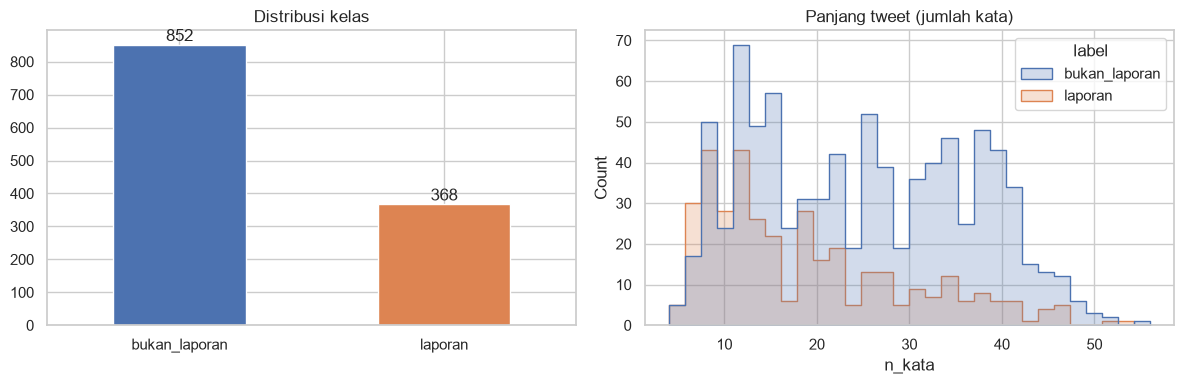

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
bukan_laporan,852.0,25.0,11.6,5.0,14.0,25.0,35.0,56.0
laporan,368.0,18.6,10.8,4.0,10.0,15.5,26.0,53.0


In [7]:
tweets["n_kata"] = tweets.text_raw.str.split().str.len()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
tweets.label.value_counts().plot.bar(ax=ax[0], color=["#4C72B0", "#DD8452"])
ax[0].set_title("Distribusi kelas"); ax[0].set_xlabel(""); ax[0].tick_params(axis="x", rotation=0)
for p in ax[0].patches:
    ax[0].annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
sns.histplot(data=tweets, x="n_kata", hue="label", bins=30, ax=ax[1], element="step")
ax[1].set_title("Panjang tweet (jumlah kata)")
plt.tight_layout(); plt.savefig(FIG / "01_distribusi_kelas.png", dpi=150); plt.show()
tweets.groupby("label").n_kata.describe().round(1)

In [8]:
tweets["punya_lokasi"] = tweets.locations.str.len() > 0
print(pd.crosstab(tweets.label, tweets.punya_lokasi, normalize="index").round(3))
top_lok = Counter(l for ls in tweets.locations for l in ls).most_common(15)
pd.DataFrame(top_lok, columns=["lokasi", "frekuensi"])

punya_lokasi   False  True 
label                      
bukan_laporan  0.222  0.778
laporan        0.019  0.981


,lokasi,frekuensi
0,jakarta,80
1,sentani,49
2,jayapura,33
3,papua,32
4,indonesia,30
5,bandung,26
6,samarinda,26
7,sulawesi selatan,21
8,bengkulu,18
9,brebes,16


## 5. Preprocessing teks
Tahapan (mengikuti alur klasifikasi teks Twitter pada soal):
1. **Case folding**: semua huruf kecil.
2. **Cleaning**: hapus URL, mention, simbol `#`, dan tanda baca. Angka diganti token `angka`, karena laporan kejadian
   sering memuat angka ("air 50 cm", "jam 06.45", "RT 03") sehingga keberadaan angka adalah sinyal penting.
3. **Normalisasi slang**: kata tidak baku → baku (kamus kecil yang relevan dengan domain).
4. **Stopword removal**: daftar stopword Sastrawi, dengan **pengecualian** kata yang penting untuk domain
   (mis. "tidak", "belum", "masih", "sudah", karena "banjir *sudah* surut" ≠ "banjir *masih* tinggi").
5. **Stemming**: algoritma Nazief–Adriani (library Sastrawi).

In [9]:
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

stemmer = StemmerFactory().create_stemmer()
STOPWORDS = set(StopWordRemoverFactory().get_stop_words())
JAGA = {"tidak", "belum", "masih", "sudah", "sedang", "naik", "turun", "tinggi", "dalam", "atas", "bawah"}
STOPWORDS -= JAGA
STOPWORDS |= {"jadi", "nya", "sih", "deh", "nih", "kok", "yah", "dong", "kan", "via", "regrann"}

SLANG = {
    "gak": "tidak", "ga": "tidak", "enggak": "tidak", "engga": "tidak", "nggak": "tidak", "ngga": "tidak", "tdk": "tidak", "gk": "tidak",
    "udah": "sudah", "udh": "sudah", "sdh": "sudah", "blm": "belum", "msh": "masih", "lg": "lagi",
    "yg": "yang", "dgn": "dengan", "dg": "dengan", "utk": "untuk", "krn": "karena", "jg": "juga",
    "bgt": "banget", "aja": "saja", "sm": "sama", "dr": "dari", "dlm": "dalam", "tp": "tapi",
    "jkt": "jakarta", "tng": "tangerang", "bks": "bekasi", "dki": "jakarta", "jl": "jalan", "jln": "jalan",
    "kel": "kelurahan", "kec": "kecamatan", "rt": "rt", "cm": "sentimeter", "skrg": "sekarang",
    "bnjr": "banjir", "bjr": "banjir", "tggi": "tinggi", "smp": "sampai", "sampe": "sampai",
}

def bersihkan(teks):
    t = teks.lower()
    t = re.sub(r"https?://\S+|www\.\S+", " ", t)
    t = re.sub(r"@\w+", " ", t)
    t = t.replace("#", " ")
    t = re.sub(r"\d+([.,:]\d+)*", " angka ", t)  # angka (tinggi air, jam, RT) jadi satu token
    t = re.sub(r"[^a-z\s]", " ", t)
    return re.sub(r"\s+", " ", t).strip()

def preprocess(teks, stem=True):
    kata = [SLANG.get(w, w) for w in bersihkan(teks).split()]
    kata = [w for w in kata if w not in STOPWORDS and len(w) > 1]
    if stem:
        kata = [stemmer.stem(w) for w in kata]
        kata = [w for w in kata if w not in STOPWORDS]  # hasil stem bisa jadi stopword (menjadi → jadi)
    return " ".join(kata)

contoh = tweets.text_raw.iloc[3]
print("ASLI     :", contoh)
print("CLEANING :", bersihkan(contoh))
print("FINAL    :", preprocess(contoh))

ASLI     : `` : video kenangan gub dki jaman old menegaskan masalah banjir bukan masalah jakarta itu kewenangan pemerintah pusat dia menegaskan jika terpilih sebagai presiden maka segala persoalan di jakarta dapat mudah teratasi ``
CLEANING : video kenangan gub dki jaman old menegaskan masalah banjir bukan masalah jakarta itu kewenangan pemerintah pusat dia menegaskan jika terpilih sebagai presiden maka segala persoalan di jakarta dapat mudah teratasi


FINAL    : video kenang gub jakarta jaman old tegas masalah banjir bukan masalah jakarta wenang perintah pusat tegas pilih presiden segala soal jakarta mudah atas


In [10]:
# Stemming kata per kata lambat, jadi cache per kata unik
_cache = {}
def stem_cepat(w):
    if w not in _cache:
        _cache[w] = stemmer.stem(w)
    return _cache[w]

def preprocess_cepat(teks):
    kata = [SLANG.get(w, w) for w in bersihkan(teks).split()]
    kata = [stem_cepat(w) for w in kata if w not in STOPWORDS and len(w) > 1]
    return " ".join(w for w in kata if w not in STOPWORDS)

assert preprocess_cepat(contoh) == preprocess(contoh)
tweets["text_clean"] = tweets.text_raw.map(preprocess_cepat)
tweets = tweets[tweets.text_clean.str.len() > 0].reset_index(drop=True)
tweets[["text_raw", "text_clean", "label"]].head(8)

,text_raw,text_clean,label
0,13 janji akan mencari solusi banjir jakarta da...,angka janji cari solusi banjir jakarta macet j...,bukan_laporan
1,ingin tenangkan diri di musim banjir ? -memanc...,tenang diri musim banjir pancing sukat air bak...,bukan_laporan
2,intensitas dan curah hujan yang tinggi telah m...,intensitas curah hujan tinggi banjir bagai dae...,bukan_laporan
3,`` : video kenangan gub dki jaman old menegask...,video kenang gub jakarta jaman old tegas masal...,bukan_laporan
4,banjir di jalan pagarsih,banjir jalan pagarsih,laporan
5,keadaan banjir di seberang jaya jam 6:45pg tadi,banjir seberang jaya jam angka pg tadi,bukan_laporan
6,sekarang nih kan musim hujan risau juga kalau ...,sekarang musim hujan risau kalau air banjir na...,bukan_laporan
7,kondisi terkini banjir luapan kali wulung di t...,kondisi kini banjir luap kali wulung isolir sa...,laporan


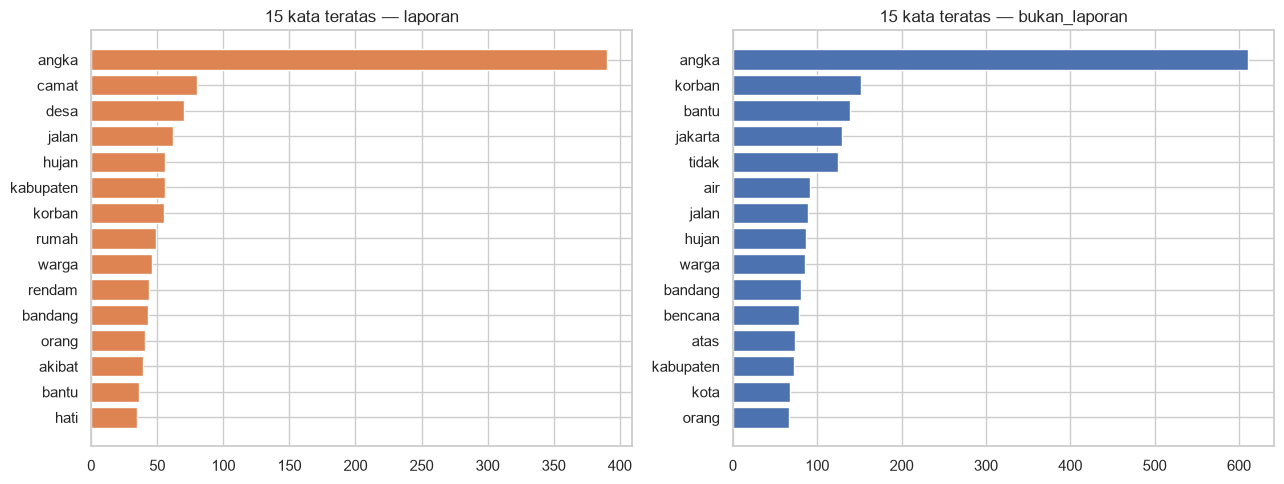

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for i, (lab, warna) in enumerate([("laporan", "#DD8452"), ("bukan_laporan", "#4C72B0")]):
    c = Counter(w for t in tweets[tweets.label == lab].text_clean for w in t.split() if w != "banjir")
    kata, frek = zip(*c.most_common(15))
    ax[i].barh(kata[::-1], frek[::-1], color=warna)
    ax[i].set_title(f"15 kata teratas — {lab}")
plt.tight_layout(); plt.savefig(FIG / "01_kata_teratas.png", dpi=150); plt.show()

**Pengamatan:**
- Kelas `laporan` didominasi kata **wilayah administratif** (camat, desa, kabupaten, jalan) dan **dampak fisik**
  (rendam, rumah, warga, korban). Laporan kejadian biasanya menyebut *di mana* dan *apa yang terdampak*.
- Kelas `bukan_laporan` didominasi kata **bantuan/donasi** (bantu, korban, bencana) dan nama kota besar (jakarta)
  yang muncul dalam konteks opini atau politik. Kata negasi **tidak** juga jauh lebih sering muncul di kelas ini
  (kalimat opini/keluhan), dan ini membuktikan keputusan untuk *tidak* membuang kata negasi saat stopword removal.
- Beberapa kata muncul di kedua kelas (korban, hujan, warga), sehingga satu kata saja tidak cukup untuk membedakan kelas.
  Model perlu mempertimbangkan kombinasi kata, dan inilah alasan memakai pembobotan TF-IDF + bigram di Notebook 2.

## 6. Pembagian data latih dan uji
Stratified split 80:20 (`random_state=42`) agar proporsi kelas sama di kedua bagian.

In [12]:
from sklearn.model_selection import train_test_split

idx_train, idx_test = train_test_split(tweets.index, test_size=0.2, stratify=tweets.label, random_state=42)
tweets["split"] = "train"
tweets.loc[idx_test, "split"] = "test"
print(pd.crosstab(tweets.split, tweets.label, margins=True))

kolom = ["id", "text_raw", "text_clean", "label", "split", "locations"]
tweets[kolom].to_json(OUT / "tweets_banjir.json", orient="records", force_ascii=False, indent=1)
print("Tersimpan:", OUT / "tweets_banjir.json")

label  bukan_laporan  laporan   All
split                              
test             170       74   244
train            682      294   976
All              852      368  1220
Tersimpan: data\processed\tweets_banjir.json


## Ringkasan
- Dataset akhir berisi tweet banjir berbahasa Indonesia dengan dua kelas: `laporan` dan `bukan_laporan` (tidak seimbang).
- Karena kelas tidak seimbang, evaluasi di Notebook 2 memakai **F1-score** sebagai metrik utama, di samping akurasi, presisi, dan recall.
- Entitas lokasi hasil anotasi disimpan untuk ekstraksi lokasi dan pemetaan di Notebook 3–4.